# Frente 3 — Carreira: trajetória e objetivos

**PRO3201 — Estatística e Aplicações · Grupo 10 (J)**

**Pergunta da frente:** como a vivência no grupo de extensão se conecta ao horizonte profissional de curto prazo (estágio e objetivo atual) e de médio prazo (área pretendida após a formatura)?

### Como ler este notebook

- **Leia como um artigo.** As células de código só chamam funções com nomes autoexplicativos (em inglês, pela convenção do README). A lógica fica em `src/`:
  - `stats_tests.py`: testes da disciplina;
  - `regression.py`: regressão linear múltipla;
  - `carreira.py`: preparação dos dados e agrupamentos;
  - `plotting/plots_carreira.py`: gráficos.
- **Cada pergunta segue os itens (a) a (e) do guia:** hipóteses; teste e premissas; resultado; gráfico ou tabela; conclusão para o relatório.
- **Métodos:** só os da disciplina (qui-quadrado, ANOVA com Bartlett e Scheffé, regressão linear com F parcial), α = 5%.
- **Perguntas do guia cortadas:**
  - P5 (o estágio derruba as horas no grupo): praticamente ninguém da amostra está estagiando;
  - P8 (prever a área pretendida): com 6 áreas, n = 187 e sem regressão logística, a previsão não se sustenta.

## 0. Preparação

*Célula técnica: só carrega as funções e os dados. Pode ser pulada na leitura.*

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR, FIG_DIR, TAB_DIR = ROOT_DIR / "data", ROOT_DIR / "output" / "figures", ROOT_DIR / "output" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import pandas as pd

from src.carreira import (AREA_ORDER, CAREER_CONTRASTS, CAREER_GROUP_ORDER, CAREER_ORDER, MAIN_VARIABLES,
                          REGRESSION_BLOCKS, REGRESSION_COLUMNS, REGRESSION_LABELS, YEAR_GROUP_ORDER, analysis_sample,
                          build_scenarios, category_distribution, grouping_table, prepare_front_data)
from src.plotting.plots_carreira import (plot_category_distribution, plot_means_panels, plot_residual_diagnostics,
                                         plot_scenario_probabilities, plot_stacked_shares)
from src.regression import (backward_elimination, coefficient_table, fit_ols, joint_partial_f_test, model_summary,
                            predict_scenarios)
from src.stats_tests import (chi_square_association, group_means, one_way_anova, row_percentages, scheffe_contrasts,
                             standardized_residuals)

pd.set_option("display.max_columns", None)
df = prepare_front_data(pd.read_parquet(DATA_DIR / "clean_data.parquet"))
print(f"{len(df)} alunos carregados.")

187 alunos carregados.


## 1. Dados e cuidados gerais

- **Base:** `clean_data.parquet` gerado de novo em 25/11, com 187 alunos da Poli, todos participantes de grupos de extensão. Na versão de 24/11, a coluna `anos_de_poli` estava desalinhada para 30 alunos. A preparação confere que ela bate com o ano de ingresso e interrompe a execução se receber um arquivo antigo.
- **A amostra é jovem:** 31 alunos no 1º ano, 93 no 2º e 63 no 3º ano ou depois (só 9 no 4º ou 5º). Por isso, **o momento do estágio mede intenção**, não um fato. A maioria ainda não chegou à idade de estagiar.
- **Agrupamentos (tabela abaixo):** o teste qui-quadrado só é confiável quando poucas caselas têm frequência esperada abaixo de 5. Usamos o mesmo critério da Frente 1: no máximo cerca de 20% das caselas. Cada agrupamento foi escolhido para cumprir esse critério, e o motivo aparece na tabela.
- **Exclusões feitas teste a teste, sem apagar linhas da base:**
  - "Outros" na motivação (n = 7) fica fora do qui-quadrado da P2;
  - "Indefinido" na área pretendida (n = 20) fica fora só da P1b;
  - as 7 respostas sem objetivo ficam fora dos testes que usam objetivo;
  - a única resposta "Não pretendo realizar estágio" fica fora da P3 e da P7.

> **Conceito — linguagem associativa.** Todos os alunos da amostra fazem extensão, e não há grupo de controle. Os testes mostram **associações** ("quem está no grupo X tende a mirar a área Y"), não efeitos causais ("o grupo X leva a mirar Y"). Também pode ser que o aluno escolha o grupo por já mirar a área.

In [2]:
groupings = grouping_table(df)
groupings.to_csv(TAB_DIR / "f3_tab02_agrupamentos.csv", index=False)
groupings

,Variável,Categorias originais,Nova categoria,n,Motivo
0,categoria_extensao,Consultoria & Negócios + Empreendedorismo,Consultoria & Negócios,108,Empreendedorismo tem n = 8; mesma decisão da F...
1,area_pretendida,Consultoria + Empreendedorismo,Consultoria & Empreendedorismo,52,"Com 6 áreas, 28% das caselas da P1a ficam com ..."
2,motivacao_ingresso,Networking e contato com empresas + Indicação ...,Outros,7,"n = 7; aparece na descritiva, mas fica fora do..."
3,objetivo_faculdade,Desempenho acadêmico + IC / Pesquisa,Desempenho & Pesquisa,33,"IC / Pesquisa tem n = 6; com 5 objetivos, 33% ..."
4,anos_de_poli,3 + 4 + 5,3º ano ou mais,63,Só 9 alunos estão no 4º ou 5º ano
5,momento_estagio,Antes do 3º ano + No 3ºano,Até o 3º ano,82,"Corte da P3 e da P7; mede intenção, pois a mai..."
6,momento_estagio,No 4ºano + A partir do 5ºano,4º ano ou depois,104,Idem
7,momento_estagio,Não pretendo realizar estágio,Excluído (sem valor),1,n = 1
8,media_ponderada,Menor que 5.0 + 5.0 a 5.9 + 6.0 a 6.9,"Abaixo de 7,0",71,Checagem ordinal da P6: as faixas das pontas t...
9,media_ponderada,8.0 a 8.9 + 9.0 a 10.0,"8,0 ou mais",41,Idem


## 2. Diagnóstico descritivo

A tabela descritiva é a `f3_tab01`, mesmo aparecendo depois da `f3_tab02`: a numeração segue a ordem de leitura do relatório, que começa pela descritiva. Os cuidados com os dados vêm antes, por isso a ordem das células.

In [3]:
descriptive = category_distribution(df, MAIN_VARIABLES)
descriptive.to_csv(TAB_DIR / "f3_tab01_descritiva.csv")
descriptive

n  \
Variável                              Categoria                                                 
Área pretendida após a formatura      Mercado Financeiro                                   49   
                                      Consultoria                                          33   
                                      Empreendedorismo                                     19   
                                      Indústria/Engenharia                                 42   
                                      Tecnologia                                           24   
                                      Indefinido                                           20   
Quando pretende fazer o 1º estágio    Até o 3º ano                                         82   
                                      4º ano ou depois                                    104   
                                      Sem resposta                                          1   
Objetivo principal atual na faculdade Desempenho acadêmico                                 27   
                                      Estágio                                              48   
                                      Grupo de extensão                                    77   
                                      IC / Pesquisa                                         6   
                                      Intercâmbio                                          22   
                                      Sem resposta                                          7   
Motivação para entrar no grupo        Adquirir experiência prática em projetos reais       46   
                                      Aprendizado técnico (hardskills)                     47   
                                      Desenvolvimento pessoal, comunicação e lideranç...   40   
                                      Interesse pela temática e objetivos do grupo         47   
                                      Outros                                                7   
Categoria do grupo de extensão        Consultoria & Negócios                              108   
                                      Engenharia                                           45   
                                      Mercado Financeiro                                   34   
Ano na Poli                           1º ano                                               31   
                                      2º ano                                               93   
                                      3º ano ou mais                                       63   

                                                                                             %  
Variável                              Categoria                                                 
Área pretendida após a formatura      Mercado Financeiro                                  26.2  
                                      Consultoria                                         17.6  
                                      Empreendedorismo                                    10.2  
                                      Indústria/Engenharia                                22.5  
                                      Tecnologia                                          12.8  
                                      Indefinido                                          10.7  
Quando pretende fazer o 1º estágio    Até o 3º ano                                        43.9  
                                      4º ano ou depois                                    55.6  
                                      Sem resposta                                         0.5  
Objetivo principal atual na faculdade Desempenho acadêmico                                14.4  
                                      Estágio                                             25.7  
                                      Grupo de extensão                                   41.2  
                 

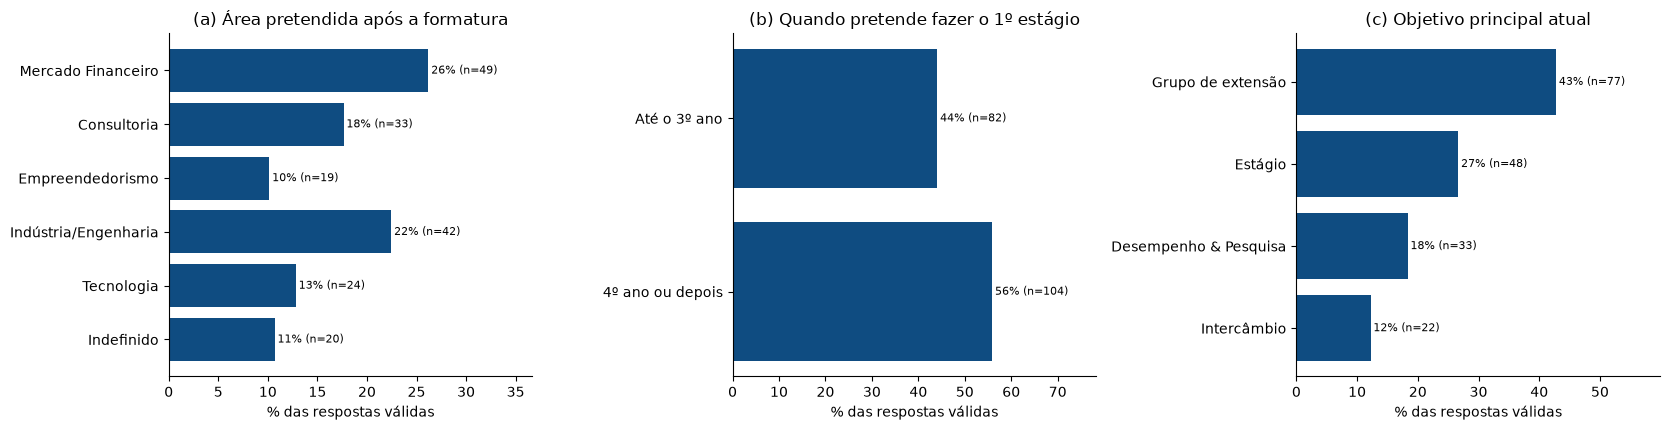

In [4]:
plot_category_distribution(df, [("area_pretendida", "(a) Área pretendida após a formatura"),
                                ("estagio_antecipado", "(b) Quando pretende fazer o 1º estágio"),
                                ("objetivo_grupo", "(c) Objetivo principal atual")],
                           FIG_DIR / "f3_fig01_distribuicao_variaveis_principais.png")

**Leitura.**

- **Área pretendida:** Mercado Financeiro é a mais citada (49 alunos; 26%), seguida de Indústria/Engenharia (42; 22%) e Consultoria (33; 18%). Só 20 alunos (11%) estão indefinidos.
- **Estágio:** 82 de 186 respondentes (44%) pretendem fazer o 1º estágio até o 3º ano e 104 (56%) só a partir do 4º. Como a amostra é jovem, isso é intenção, não fato.
- **Objetivo atual:** "Grupo de extensão" é o mais comum (77 de 180; 43%), à frente de Estágio (48; 27%). Intercâmbio tem 22 (12%) e Desempenho acadêmico e IC/Pesquisa juntos, 33 (18%).
- **Perfil da amostra:** 31 alunos no 1º ano (17%), 93 no 2º (50%) e 63 no 3º ano ou mais (34%); 108 (58%) estão em grupos de Consultoria & Negócios.